## Name: Aman Mujahid
## Github Username: amanmujahid
## USC ID: 7092517106

### Question-1

#### (a)

In [1]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import tree


cols = ['temperature', 'nausea', 'lumbar', 'urine_push', 'micturition', 'urethra_burn', 'bladder', 'nephritis']
df = pd.read_csv('../data/acute+inflammations/diagnosis.data', sep='\t', header=None, names=cols, decimal=',', encoding='utf-16')


df[cols[1:]] = (df[cols[1:]] == 'yes').astype(int)


X = df.drop(columns=['bladder', 'nephritis'])

y = df['bladder'].astype(str) + df['nephritis'].astype(str)
df.head()

,temperature,nausea,lumbar,urine_push,micturition,urethra_burn,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


#### (b)

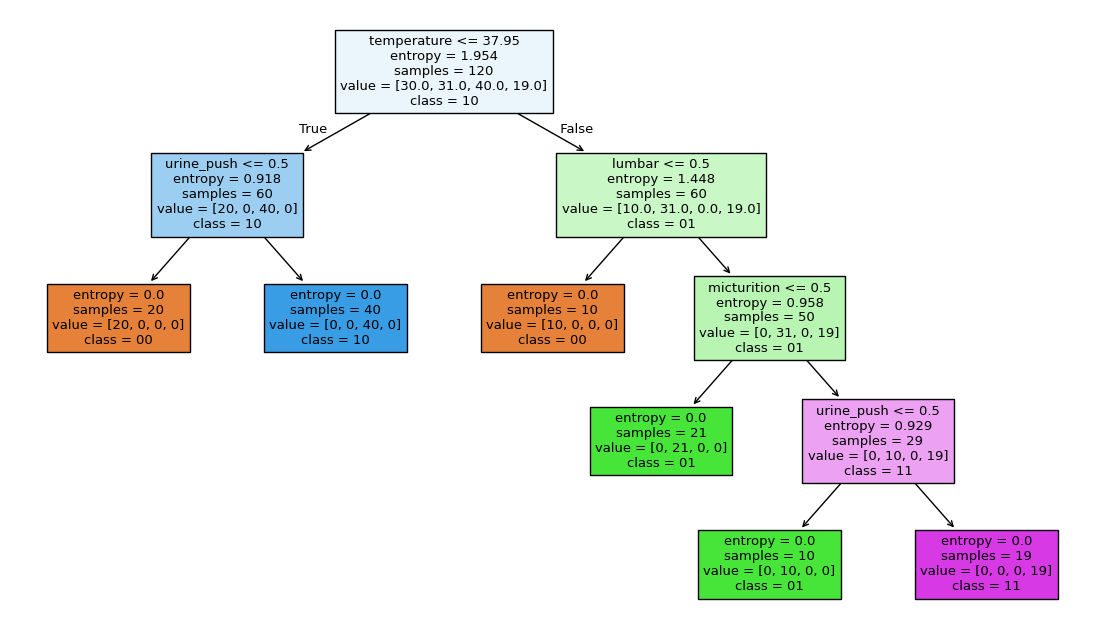

In [2]:
dt = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)
dt.fit(X, y)

plt.figure(figsize=(14, 8))

tree.plot_tree(dt, feature_names=list(X.columns), class_names=dt.classes_, filled=True)
plt.show()

#### (c)

In [3]:
def tree_to_pseudo(tree, feature_names):
	left = tree.tree_.children_left
	right = tree.tree_.children_right
	threshold = tree.tree_.threshold
	features = [feature_names[i] for i in tree.tree_.feature]
	value = tree.tree_.value

	def recurse(left, right, threshold, features, node, depth=0):
        
		indent = "  " * depth
        
		if (threshold[node]!=-2):
			print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
            
			if left[node]!=-1:
				recurse (left, right, threshold, features, left[node], depth+1)
				print(indent,"} else {")
                
				if right[node]!=-1:
					recurse (left, right, threshold, features, right[node], depth+1)
				print(indent,"}")
                
		else:
			print(indent,"return " + str(tree.classes_[value[node].argmax()]))

    
	recurse(left, right, threshold, features, 0)



tree_to_pseudo(dt, list(X.columns))

 if ( temperature <= 37.95000076293945 ) {
   if ( urine_push <= 0.5 ) {
     return 00
   } else {
     return 10
   }
 } else {
   if ( lumbar <= 0.5 ) {
     return 00
   } else {
     if ( micturition <= 0.5 ) {
       return 01
     } else {
       if ( urine_push <= 0.5 ) {
         return 01
       } else {
         return 11
       }
     }
   }
 }


#### (d)

      alpha  leaves  cv_accuracy
0  0.000000       6     1.000000
1  0.199592       4     0.866667
2  0.325011       3     0.766667
3  0.459148       2     0.616667
4  0.770426       1     0.541667

best alpha: 0.0
leaves: 6  depth: 4


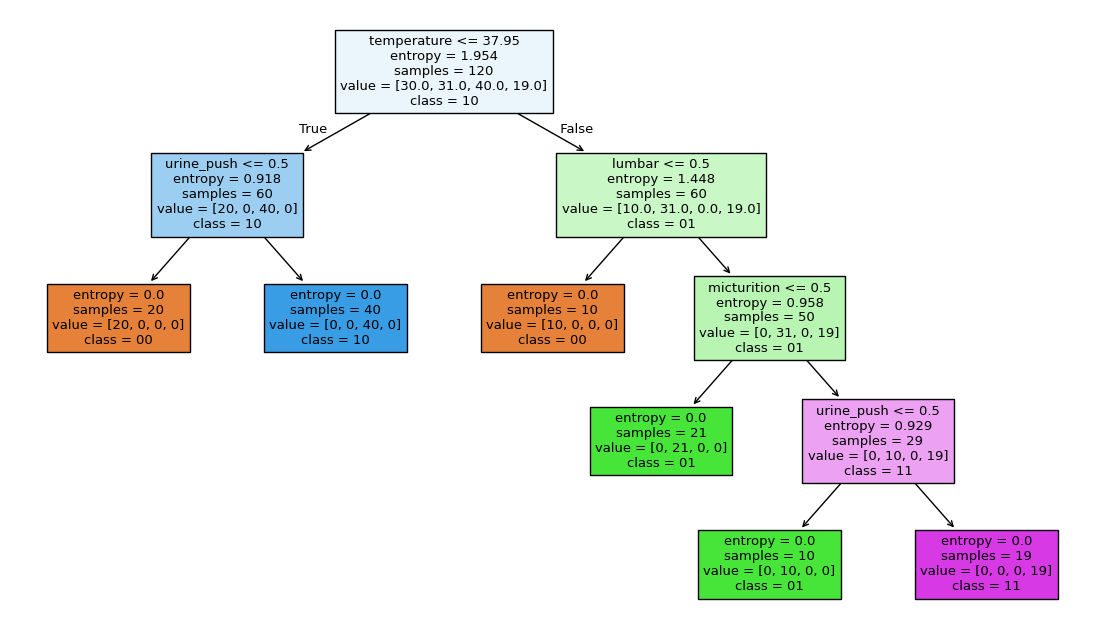

 if ( temperature <= 37.95000076293945 ) {
   if ( urine_push <= 0.5 ) {
     return 00
   } else {
     return 10
   }
 } else {
   if ( lumbar <= 0.5 ) {
     return 00
   } else {
     if ( micturition <= 0.5 ) {
       return 01
     } else {
       if ( urine_push <= 0.5 ) {
         return 01
       } else {
         return 11
       }
     }
   }
 }


In [4]:
path = dt.cost_complexity_pruning_path(X, y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

grid = GridSearchCV(tree.DecisionTreeClassifier(criterion='entropy', random_state=0), {'ccp_alpha': path.ccp_alphas}, cv=cv)
grid.fit(X, y)

leaves = [tree.DecisionTreeClassifier(criterion='entropy', random_state=0, ccp_alpha=a).fit(X, y).get_n_leaves() for a in path.ccp_alphas]
print(pd.DataFrame({'alpha': path.ccp_alphas, 'leaves': leaves, 'cv_accuracy': grid.cv_results_['mean_test_score']}))

pruned = grid.best_estimator_
print()
print('best alpha:', grid.best_params_['ccp_alpha'])
print('leaves:', pruned.get_n_leaves(), ' depth:', pruned.get_depth())

plt.figure(figsize=(14, 8))
tree.plot_tree(pruned, feature_names=list(X.columns), class_names=pruned.classes_, filled=True)
plt.show()

tree_to_pseudo(pruned, list(X.columns))

Here, cross-validation picked alpha=0 as any pruning beyond that lost accuracy, so the full tree with 6 leaves and depth 4 is already the minimal decision tree. It gives 6 IF-THEN rules using only 4 features, which is quite easy to interpret.

### Question-2

#### (a)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt


path = '../data/communities+and+crime/'

names = []
for line in open(path + 'communities.names'):
    if line.startswith('@attribute'):
        names.append(line.split()[1])


df = pd.read_csv(path + 'communities.data', header=None, names=names, na_values='?')

train, test = df.iloc[:1495], df.iloc[1495:]

print(train.shape, test.shape)

(1495, 128) (499, 128)


#### (b)

In [6]:
nonpredictive = ['state', 'county', 'community', 'communityname', 'fold']

train = train.drop(columns=nonpredictive)
test = test.drop(columns=nonpredictive)
train = train.fillna(train.mean())
test = test.fillna(train.mean())


X_train, y_train = train.drop(columns='ViolentCrimesPerPop'), train['ViolentCrimesPerPop']
X_test, y_test = test.drop(columns='ViolentCrimesPerPop'), test['ViolentCrimesPerPop']

#### (c)

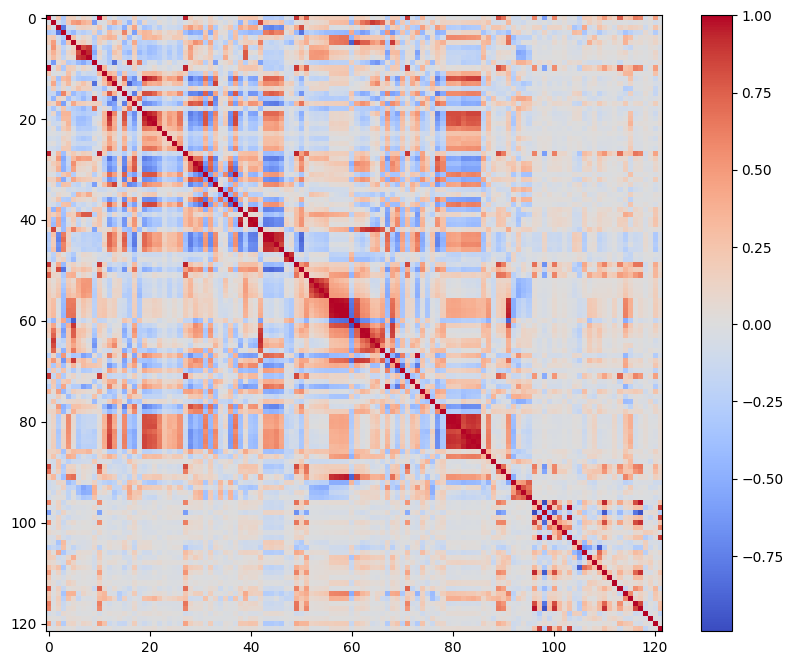

In [7]:
plt.figure(figsize=(10, 8))
plt.imshow(X_train.corr(), cmap='coolwarm')
plt.colorbar()
plt.show()

#### (d)

In [8]:
cv = (X_train.std()/X_train.mean())
cv.sort_values(ascending=False)

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
                         ...   
NumKindsDrugsSeiz      0.144382
RacialMatchCommPol     0.134853
PctPolicWhite          0.122813
LemasPctPolicOnPatr    0.115739
LemasSwFTFieldOps      0.064288
Length: 122, dtype: float64

#### (e)

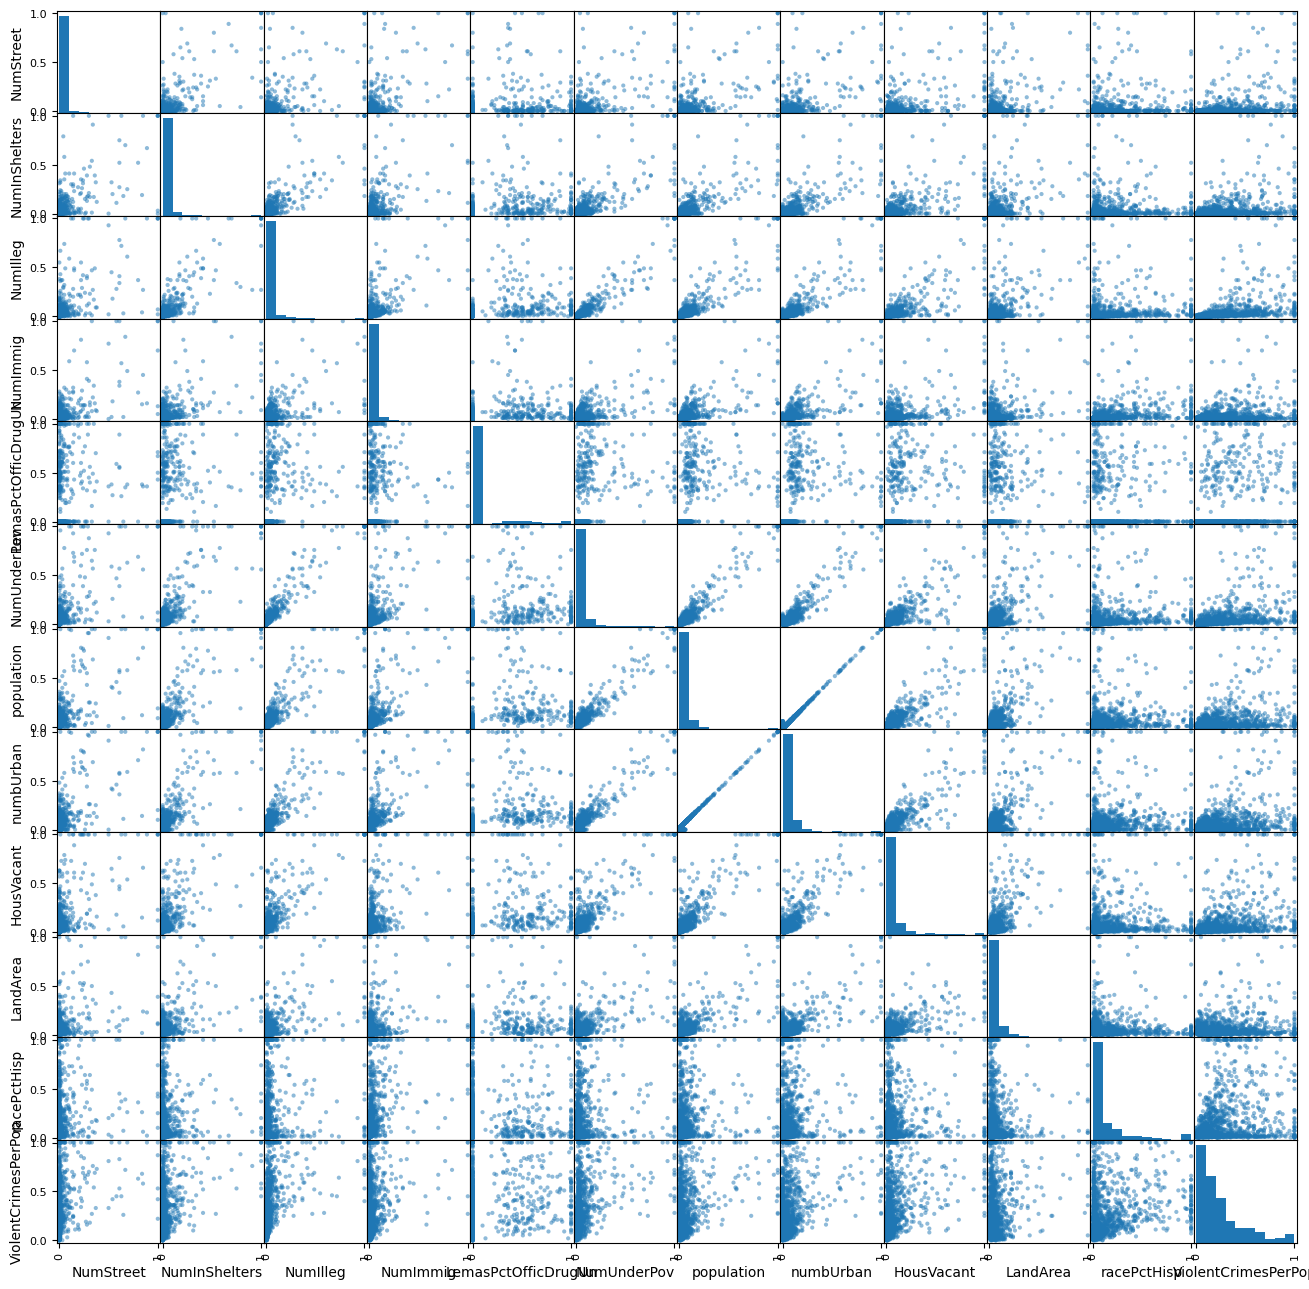

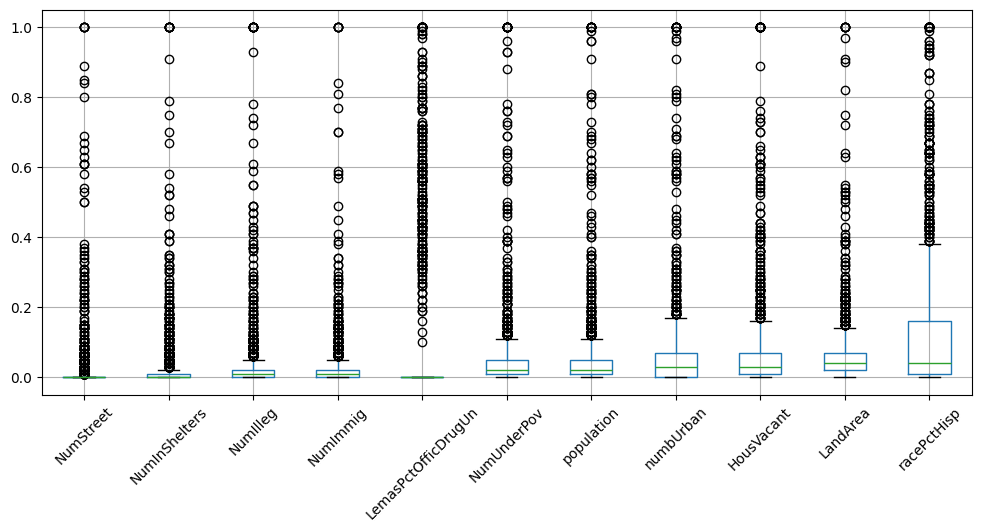

In [9]:
top = cv.nlargest(int(128**0.5)).index


pd.plotting.scatter_matrix(train[list(top)+['ViolentCrimesPerPop']], figsize=(16, 16))
plt.show()

X_train[top].boxplot(figsize=(12, 5), rot=45)
plt.show()

No, we cannot draw a conclusion here. Because in the scatter matrix, we cannot see any proper trend between these features and the crime rate in the bottom row. Also, most values of these 11 features sit close to 0. Now, this doesn’t tell us if a feature here is significant, for which a fitted model or a statistical test is needed.

#### (f)

In [10]:
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression


least_squares = LinearRegression().fit(X_train, y_train)
print('test MSE:', mean_squared_error(y_test, least_squares.predict(X_test)))

test MSE: 0.01814197113553011


#### (g)

In [11]:
import numpy as np
from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=np.logspace(-4, 4, 50), cv=5).fit(X_train, y_train)


print('best lambda:', ridge.alpha_)
print('test MSE:', mean_squared_error(y_test, ridge.predict(X_test)))

best lambda: 2.559547922699533
test MSE: 0.017584575803949405


#### (h)

In [12]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

lasso = LassoCV(cv=5, random_state=0).fit(X_train, y_train)

selected = []
for feature, coefficient in zip(X_train.columns, lasso.coef_):
    if coefficient != 0:
        selected.append(feature)

print('LASSO without standardization')
print('best lambda:', lasso.alpha_)
print('test MSE:', mean_squared_error(y_test, lasso.predict(X_test)))
print('number of selected features:', len(selected))
print('selected features:', selected)


scaler = StandardScaler().fit(X_train)
X_train_standardized, X_test_standardized = scaler.transform(X_train), scaler.transform(X_test)

lasso_standardized = LassoCV(cv=5, random_state=0).fit(X_train_standardized, y_train)

selected_standardized = []
for feature, coefficient in zip(X_train.columns, lasso_standardized.coef_):
    if coefficient != 0:
        selected_standardized.append(feature)

print()
print('LASSO with standardization')
print('best lambda:', lasso_standardized.alpha_)
print('test MSE:', mean_squared_error(y_test, lasso_standardized.predict(X_test_standardized)))
print('number of selected features:', len(selected_standardized))
print('selected features:', selected_standardized)

LASSO without standardization

C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.753e-03, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.011e-02, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(



best lambda: 0.00011614723626829846
test MSE: 0.017758209216319674
number of selected features: 75
selected features: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'N

C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.827e-03, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.021e-02, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\mujah\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or c

Here, without standardizing, LASSO kept 75 features with a test MSE of 0.017758209216319674. With standardized features, it kept 73 features with a test MSE of 0.017805339276862273. Both results are almost the same since the features here are already normalized to 0 to 1. Therefore, standardizing didn’t change much here in terms of test error or the number of features selected.

#### (i)

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA


pcr = GridSearchCV(make_pipeline(PCA(), LinearRegression()), {'pca__n_components': range(1, 123)}, cv=5, scoring='neg_mean_squared_error').fit(X_train, y_train)


print('best M:', pcr.best_params_['pca__n_components'])
print('test MSE:', mean_squared_error(y_test, pcr.predict(X_test)))

best M: 96
test MSE: 0.01847177851616836


#### (j)

In [14]:
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score


alphas = [0, 0.001, 0.01, 0.1, 1, 10]

cv_errors = []
for alpha in alphas:
    scores = cross_val_score(XGBRegressor(random_state=0, reg_alpha=alpha), X_train, y_train,
                             cv=5, scoring='neg_mean_squared_error')
    
    cv_errors.append(-scores.mean())


print(pd.DataFrame({'alpha': alphas, 'cv_MSE': cv_errors}))


best_alpha = alphas[np.argmin(cv_errors)]
xgb = XGBRegressor(random_state=0, reg_alpha=best_alpha).fit(X_train, y_train)


print('best alpha:', best_alpha)
print('test MSE:', mean_squared_error(y_test, xgb.predict(X_test)))

    alpha    cv_MSE
0   0.000  0.023871
1   0.001  0.023894
2   0.010  0.023621
3   0.100  0.023731
4   1.000  0.021596
5  10.000  0.022433
best alpha: 1
test MSE: 0.017747461401957192


Here, using 5-fold cross-validation on the alpha values I tried, α = 1 gave the lowest CV error, which is around 0.0216, so this was used as the regularization term. With α = 1, the boosting tree received a test MSE of 0.017747461401957192.